# ЛР2: единая базовая модель

TF-IDF + LogisticRegression, нормализованные дубли удаляются до стратифицированного split 80/20, seed=42. Источник и ограничения данных описаны в README. Исходные SMS в публичный ноутбук не выводятся.

In [1]:
from pathlib import Path
import sys, json
root = Path.cwd()
if root.name == 'notebooks':
    root = root.parent
sys.path.insert(0, str(root))
from src.data_utils import load_and_check
df, info = load_and_check()
print(json.dumps(info, ensure_ascii=False, indent=2))


{
  "dataset_path": "data/SMSSpamCollection",
  "dataset_sha256": "7d039a24a6083ed9ef0f806ebad56bbb976e3aeb8de05669173bfdc4996c239d",
  "reference": "data/dataset.sha256",
  "original_rows": 5572,
  "duplicates_removed": 415,
  "conflicting_label_rows_removed": 0,
  "remaining_rows": 5157,
  "class_counts": {
    "ham": 4515,
    "spam": 642
  },
  "missing_values": 0,
  "empty_messages": 0,
  "label_values": [
    "ham",
    "spam"
  ],
  "feature_types": {
    "message": "string",
    "label": "string"
  }
}


## Обучение и сравнение с большинством

Преобразования обучаются только на train. Для несбалансированных классов основная метрика — F1 spam; обе метки и ограничения репрезентативности учитываются.

In [2]:
from src.train import train_and_evaluate
results = train_and_evaluate()


Reload sanity: spam
{
  "train_size": 4125,
  "test_size": 1032,
  "metrics": {
    "accuracy": 0.9786821705426356,
    "precision_spam": 0.8955223880597015,
    "recall_spam": 0.9375,
    "f1_spam": 0.916030534351145,
    "per_class": {
      "ham": {
        "precision": 0.9910913140311804,
        "recall": 0.9845132743362832,
        "f1": 0.9877913429522752
      },
      "spam": {
        "precision": 0.8955223880597015,
        "recall": 0.9375,
        "f1": 0.916030534351145
      }
    }
  },
  "dummy": {
    "accuracy": 0.875968992248062,
    "precision_spam": 0.0,
    "recall_spam": 0.0,
    "f1_spam": 0.0,
    "per_class": {
      "ham": {
        "precision": 0.875968992248062,
        "recall": 1.0,
        "f1": 0.9338842975206612
      },
      "spam": {
        "precision": 0.0,
        "recall": 0.0,
        "f1": 0.0
      }
    }
  }
}


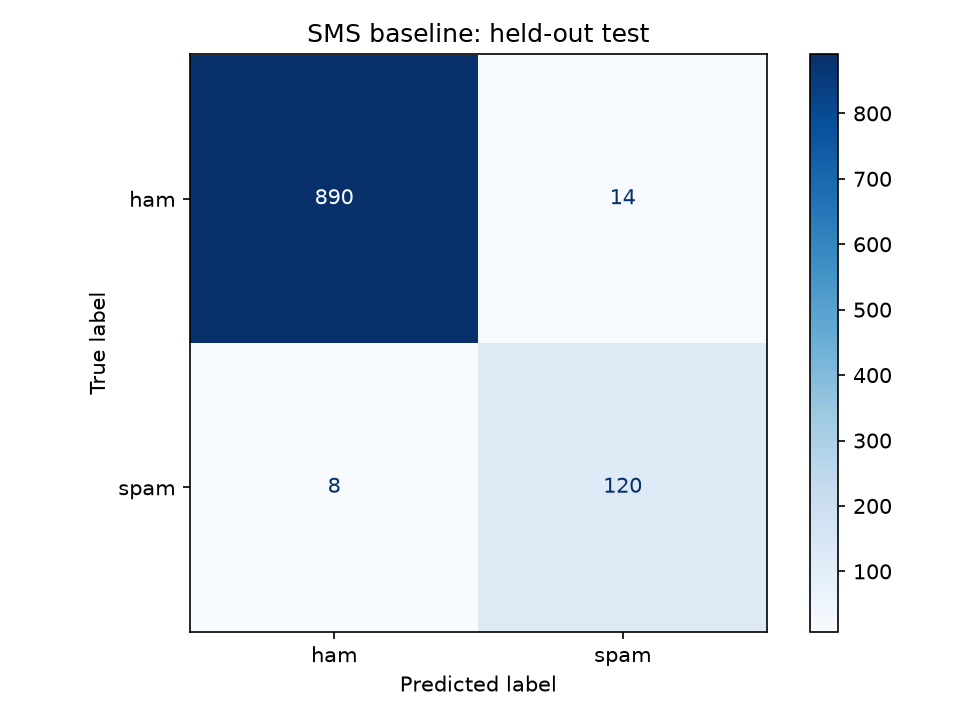

In [3]:
from IPython.display import Image, display
display(Image(filename=str(root / 'metrics/confusion_matrix.png')))


## Ошибки и ограничения

FP — обычные SMS, ошибочно помеченные как spam; FN — пропущенный spam. Тексты ошибок сохраняются только локально в metrics/errors_private.csv. Лексические признаки не учитывают намерение и контекст, короткие сообщения могут быть неоднозначны. Англоязычный исторический набор не подтверждает качество на современных русскоязычных сообщениях; близкие кампании не гарантированно независимы. Ни тестовый набор, ни показанные ошибки не используются для подбора параметров.

In [4]:
import pandas as pd
errors = pd.read_csv(root / 'metrics/errors_private.csv')
print('Количество ошибок:', len(errors))
print(errors.groupby(['label','prediction']).size())
# Анализ нескольких ошибок без публикации исходного текста:
for item in errors.head(5).itertuples():
    text = str(item.message)
    tokens = results['vectorizer_parameters']
    print({'row_id': int(item.row_id), 'actual': item.label, 'predicted': item.prediction, 'characters': len(text), 'words': len(text.split())})


Количество ошибок: 22
label  prediction
ham    spam          14
spam   ham            8
dtype: int64
{'row_id': 3476, 'actual': 'ham', 'predicted': 'spam', 'characters': 58, 'words': 12}
{'row_id': 3332, 'actual': 'ham', 'predicted': 'spam', 'characters': 24, 'words': 5}
{'row_id': 3173, 'actual': 'spam', 'predicted': 'ham', 'characters': 78, 'words': 15}
{'row_id': 1029, 'actual': 'ham', 'predicted': 'spam', 'characters': 24, 'words': 5}
{'row_id': 1618, 'actual': 'ham', 'predicted': 'spam', 'characters': 23, 'words': 5}


## Устойчивость

Парные небольшие изменения на 20 объектах настоящего test; нет пересечений с train. Дополнительная массовая замена букв цифрами — отдельный усиленный стресс-сценарий. Нетипичный синтетический вход проверяется отдельно. Результат не доказывает устойчивость ко всем атакам.

In [5]:
from src.robustness import run
robustness = run()


{
  "sample_size": 20,
  "sample_ids": [
    5057,
    2768,
    1847,
    3427,
    1821,
    2756,
    2727,
    3109,
    817,
    2549,
    3599,
    2628,
    5038,
    297,
    2190,
    99,
    610,
    1143,
    1492,
    3839
  ],
  "selection": "10 spam + 10 ham from the canonical held-out test; selection fixed before prediction",
  "seed": 42,
  "sample_train_overlap": 0,
  "model_file": "models/spam_pipeline.joblib",
  "model_sha256": "f054edc2c35248ad9cb26a78ce7d8be044558fe39d3d73d8cf487777bbfeb06a",
  "dataset_sha256": "7d039a24a6083ed9ef0f806ebad56bbb976e3aeb8de05669173bfdc4996c239d",
  "split_fingerprints": {
    "train": "2f44721bcf320c4790d71c2c73e1803e9e25925c80005d3520a22a593fe5e1b2",
    "test": "1f4049c132707c8d11a81382eb28dac88cc23ab5a4d2465595aa8f88008051cc"
  },
  "experiments": {
    "case_spaces": {
      "changed_predictions": 0,
      "changed_fraction": 0.0,
      "before": {
        "accuracy": 0.95,
        "precision_spam": 1.0,
        "recall_spam": 0

## Вывод

Модель сравнивается с DummyClassifier, метрики и хэши сохраняются. Отсутствие чувствительности к регистру/пробелам ожидаемо для TF-IDF. Другие изменения оцениваются по фактическим числам выше. Возможная мера — исследовать нормализацию замен на validation/CV внутри train, не подстраивая защиту по test. Для входов без словарных признаков предложена отдельная политика отказа. Тесты используют настоящую модель; полный текущий отчёт — docs/lab2-results.md.